**CS 4140 – Deep Learning · L06 · CNNs I: local structure and shared filters** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L06_cnns-1/L06_cnn_filters.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L06_cnns-1"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CNN I demo: from hand-made to learned filters

CS 4140 Deep Learning · Lecture 6

1. PyTorch's convolution reproduces the examples on the Edge Detection slides.
2. Hand-made edge filters on a real photo.
3. The first-layer filters a network learned on its own, and its feature maps on the same photo.

Runs in under a minute on a laptop. The first run downloads ResNet-18's weights (45 MB).
Put your own photo next to the notebook as `campus.jpg` to use it instead of the built-in sample.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image

PHOTO = Path('campus.jpg')          # any photo works; without one we use scikit-image's sample
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cpu


## 1. The Edge Detection examples in PyTorch

`F.conv2d` expects tensors shaped (batch, channels, height, width), hence the `[None, None]`.

In [2]:
vertical = torch.tensor([[1., 0., -1.]] * 3)

edge = torch.tensor([[10., 10., 10., 0., 0., 0.]] * 6)
print('Vertical Edge Detection (bright left, dark right):')
print(F.conv2d(edge[None, None], vertical[None, None])[0, 0].int())

example = torch.tensor([[3., 0, 1, 2, 7, 4], [1, 5, 8, 9, 3, 1], [2, 7, 2, 5, 1, 3],
                       [0, 1, 3, 1, 7, 8], [4, 2, 1, 6, 2, 8], [2, 4, 5, 2, 3, 9]])
print('Edge Detection, the 6 x 6 example:')
print(F.conv2d(example[None, None], vertical[None, None])[0, 0].int())

Vertical Edge Detection (bright left, dark right):
tensor([[ 0, 30, 30,  0],
        [ 0, 30, 30,  0],
        [ 0, 30, 30,  0],
        [ 0, 30, 30,  0]], dtype=torch.int32)
Edge Detection, the 6 x 6 example:
tensor([[ -5,  -4,   0,   8],
        [-10,  -2,   2,   3],
        [  0,  -2,  -4,  -7],
        [ -3,  -2,  -3, -16]], dtype=torch.int32)


Deep-learning libraries compute *cross-correlation* and call it convolution: the filter is not flipped.
A textbook convolution flips the filter first. Here that turns the 30s into −30s: the numbers the second
Vertical Edge Detection slide gets for an edge that goes from dark to light.

In [3]:
flipped = torch.flip(vertical, dims=[0, 1])
print(F.conv2d(edge[None, None], flipped[None, None])[0, 0].int())

tensor([[  0, -30, -30,   0],
        [  0, -30, -30,   0],
        [  0, -30, -30,   0],
        [  0, -30, -30,   0]], dtype=torch.int32)


## 2. Hand-made filters on a real photo

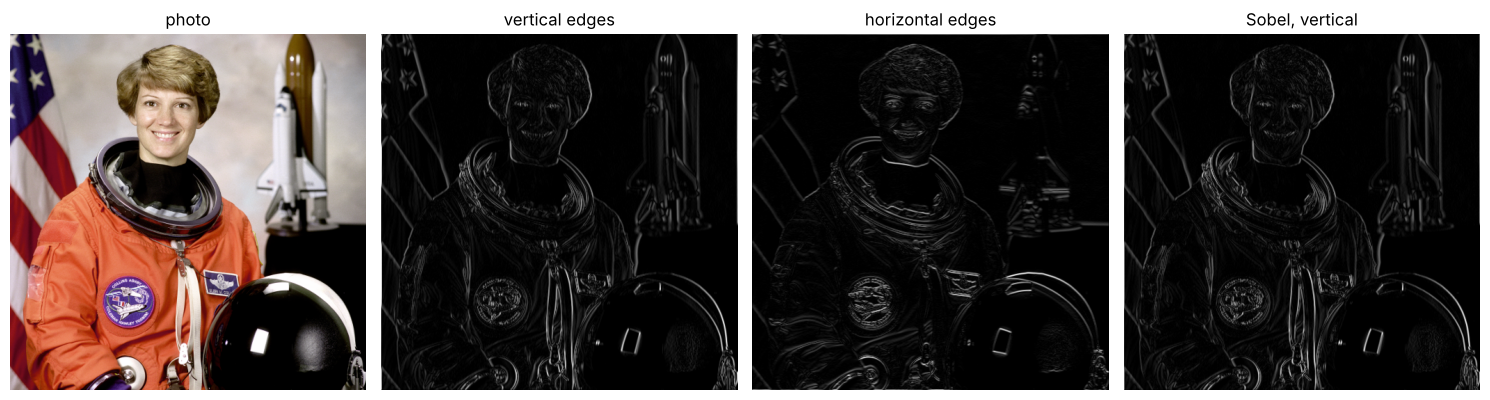

In [4]:
if PHOTO.exists():
    photo = Image.open(PHOTO).convert('RGB')
else:
    from skimage import data
    photo = Image.fromarray(data.astronaut())       # public-domain NASA portrait
photo.thumbnail((512, 512))
gray = torch.tensor(np.asarray(photo.convert('L')), dtype=torch.float32) / 255

filters = {
    'vertical edges': [[1, 0, -1]] * 3,
    'horizontal edges': [[1, 1, 1], [0, 0, 0], [-1, -1, -1]],
    'Sobel, vertical': [[1, 0, -1], [2, 0, -2], [1, 0, -1]],
}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
axes[0].imshow(photo)
axes[0].set_title('photo')
for ax, (name, k) in zip(axes[1:], filters.items()):
    k = torch.tensor(k, dtype=torch.float32)
    edges = F.conv2d(gray[None, None], k[None, None], padding=1)[0, 0]
    ax.imshow(edges.abs(), cmap='gray')
    ax.set_title(name)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. What a trained network learned on its own

ResNet-18 was trained on 1.2 million ImageNet photos. Nobody designed its first-layer filters:
backpropagation found them. Each filter below is 7 × 7 × 3, shown as a small colour image.

first-layer filters: (64, 3, 7, 7)


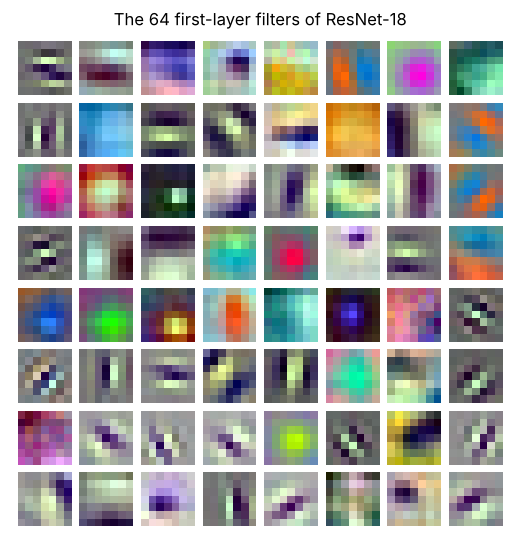

In [5]:
weights = torchvision.models.ResNet18_Weights.DEFAULT
net = torchvision.models.resnet18(weights=weights).eval()
w = net.conv1.weight.detach()                         # 64 filters, each 3 x 7 x 7
print('first-layer filters:', tuple(w.shape))

lo = w.amin(dim=(1, 2, 3), keepdim=True)
hi = w.amax(dim=(1, 2, 3), keepdim=True)
grid = torchvision.utils.make_grid((w - lo) / (hi - lo), nrow=8, padding=1, pad_value=1.0)
plt.figure(figsize=(6.5, 6.5))
plt.imshow(grid.permute(1, 2, 0), interpolation='nearest')
plt.axis('off')
plt.title('The 64 first-layer filters of ResNet-18')
plt.savefig('learned_filters.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Its feature maps on the same photo

Each filter produces one feature map. Bright means "my pattern is here".

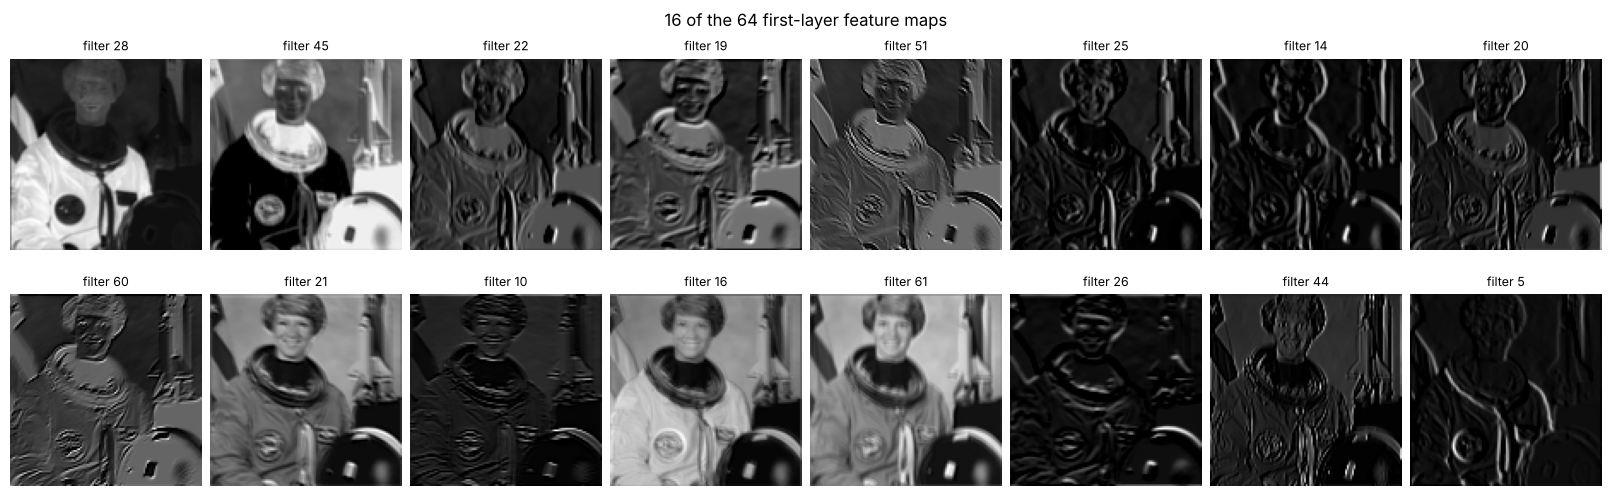

In [6]:
x = weights.transforms()(photo).unsqueeze(0)          # the resize, crop and normalisation used in training
with torch.no_grad():
    maps = torch.relu(net.bn1(net.conv1(x)))[0]      # 64 maps of 112 x 112
busiest = maps.flatten(1).std(dim=1).argsort(descending=True)[:16]
fig, axes = plt.subplots(2, 8, figsize=(16, 5), layout='constrained')
for ax, k in zip(axes.flat, busiest):
    ax.imshow(maps[k], cmap='gray')
    ax.set_title(f'filter {int(k)}', fontsize=9)
    ax.axis('off')
fig.suptitle('16 of the 64 first-layer feature maps')
plt.savefig('feature_maps.png', dpi=200, bbox_inches='tight')
plt.show()

## What to take away

Backpropagation found edge detectors at many angles, colour-contrast detectors and blob detectors:
the kinds of filters we designed by hand, plus many we have no name for. That is the idea on the
"Which filters to use?" slide, letting the network learn its filters, seen in a real network.